<div style="background-color: #FFFF00; color: #000000; padding: 12px 18px; font-family: Arial, Helvetica, sans-serif;">
<strong style="color: #000000;">MINE-4101 Ciencia de Datos Aplicada · Universidad de los Andes · 2026-20</strong><br>
<span style="color: #000000;">Proyecto final · Entrega final · Actividad 9</span>
</div>

# Estrategia de validación y selección del modelo

Cómo se entrenan, comparan y eligen los modelos, y la partición de los datos en entrenamiento, validación y prueba.

**Integrantes**

- Daniel Felipe Triviño Santana
- Nicolas Bedoya Figueroa
- Joubert Daniel Álvarez
- Gabriel Bejarano

**Qué pide el enunciado** (actividad 9, 5 % de la entrega final): definir la estrategia de experimentación para entrenar y seleccionar el mejor modelo, separar los datos en entrenamiento, validación y prueba, y un reporte breve que verifique que los subconjuntos conservan la distribución del conjunto original.

**Punto de partida:** el enfoque analítico de la primera entrega (sección 4 del [reporte](../reporte/reporte.pdf)) propuso una partición estratificada, porque solo hay una transición entre vigencias (de 2025 a 2026) y no alcanza para una validación temporal. Lee los datos del [notebook 08](08-preparacion-de-datos.ipynb).

**Cómo hacerlo:** el [sitio de prácticas del curso](https://datascience-uniandes.github.io/PracticasMachineLearning/) es la referencia principal; para esta actividad, las guías [división de los datos](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/division-datos/), [validación cruzada](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/validacion-cruzada/), [selección de hiperparámetros](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/seleccion-hiperparametros/), [GridSearchCV](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/gridsearchcv/) y [chi-cuadrado](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/chi-cuadrado/). Si el notebook se aparta de ellas, lo dice y explica por qué.

**Estado:** las seis etapas tienen código e interpretación. Pendiente de revisión del equipo.

## Tabla de contenido

| | Etapa | Qué se hace |
| --- | --- | --- |
| 1 | [Librerías y configuración](#librerias) | Librerías, rutas y estilo |
| 2 | [Carga de los datos preparados](#carga) | Leer la salida del notebook 08 |
| 3 | [Estrategia de experimentación](#estrategia) | Cómo se eligen los hiperparámetros y el mejor modelo |
| 4 | [Partición](#particion) | Entrenamiento, validación y prueba, estratificada |
| 5 | [Verificación de las distribuciones](#distribucion) | Comparar cada subconjunto con el conjunto completo |
| 6 | [Guardar la partición](#guardar) | El archivo que lee el notebook 10 |

<a id="librerias"></a>

## 1. Librerías y configuración

Las librerías están en el entorno del proyecto (ver el [README](../../README.md#entorno-de-python)). Las rutas de los archivos que pasan de un notebook a otro, la semilla y las columnas reservadas están en [utilidades_modelado.py](utilidades_modelado.py), junto a este notebook.

In [1]:
import platform

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split

# Rutas, semilla, columnas reservadas y estilo (utilidades_modelado.py, en esta carpeta)
import utilidades_modelado as um

um.configurar()

In [2]:
# Versiones con las que se ejecutó el notebook
print(f"Python {platform.python_version()}")
for libreria in (np, pd, mpl, sns, sklearn):
    print(f"{libreria.__name__} {libreria.__version__}")

Python 3.12.15
numpy 2.3.5
pandas 2.3.3
matplotlib 3.10.0
seaborn 0.13.2
sklearn 1.9.1


<a id="carga"></a>

## 2. Carga de los datos preparados

**Salidas.** El repositorio es público: ninguna salida puede mostrar datos personales ni nada que identifique al municipio, y los valores de `um.COLUMNAS_RESERVADAS` no se muestran (ver la etapa 2 del [notebook 06](../../entrega-1/notebooks/06-entendimiento-de-los-datos.ipynb)). La variable objetivo y las que salen de la facturación se muestran solo agregadas.

In [3]:
um.exigir(um.ARCHIVO_PREPARADO, "ejecute antes el notebook 08-preparacion-de-datos.ipynb")
preparados = pd.read_parquet(um.ARCHIVO_PREPARADO)
preparados.shape

(18802, 29)

<a id="estrategia"></a>

## 3. Estrategia de experimentación

- **Partición única 70/15/15** en entrenamiento, validación y prueba ([división de los datos](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/division-datos/)). Solo hay una transición entre vigencias (de 2025 a 2026), así que no hay cómo validar en el tiempo; la partición es aleatoria, pero entre grupos de predios.
- **Por grupos: los predios de un mismo dueño grande van juntos.** Hay dueños con cientos de predios que pagan todos o no paga ninguno. Con una partición al azar entre predios, el modelo ve en entrenamiento qué hizo ese dueño en 2026 y lo "predice" en validación: acierta por reconocer al dueño, no por haber aprendido. Una revisión externa del trabajo lo detectó, y el notebook 10 (etapa 4) muestra cuánto cambia la evaluación. El grupo de cada predio (`um.GRUPO_PARTICION`) lo define el notebook 08: el dueño grande (10 o más predios) o, si no lo tiene, el propio predio. Es la idea de `GroupKFold` de scikit-learn. Agrupar también por edificio se probó y se descartó: los condominios grandes caían enteros en un subconjunto y desbalanceaban la composición (en prueba quedaba 2,5 % de unidades de condominio frente a 14,8 % en entrenamiento).
- **Estratificada por el pago de 2026, el historial de 2025 y la condición del predio** (régimen), para que cada subconjunto conserve la tasa de pago de cada grupo, las métricas por grupo del notebook 10 se calculen sobre la misma composición, y la mezcla de NPH, PH, condominio e informales no dependa de qué dueños caen en cada lado. Estratificar y agrupar a la vez con grupos tan grandes no lo resuelve bien `StratifiedGroupKFold`, así que `um.particion_por_grupos` reparte primero los grupos de varios predios al azar y completa cada estrato con los predios sueltos (etapa 4).
- **Selección de hiperparámetros en validación.** Cada algoritmo se entrena con varios conjuntos de hiperparámetros sobre entrenamiento y se compara en validación ([selección de hiperparámetros](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/seleccion-hiperparametros/)). Con unos 13 000 predios en entrenamiento y 2 800 en validación, un solo conjunto de validación da estimaciones razonables, pero con grupos grandes la cifra depende de qué dueños caen en validación; el notebook 10 lo tiene en cuenta al leer diferencias pequeñas.
- **Criterio de elección: log-loss en validación.** El producto usa las probabilidades para el recaudo esperado, así que importa que estén bien calibradas. El ROC-AUC y la curva de calibración, en total y por grupo, acompañan la decisión. Todos se comparan con la línea base: la tasa de pago de cada historial en entrenamiento (la versión probabilística de repetir el pago de 2025).
- **Precisión, recall y F1 de la clase "no paga".** La Alcaldía actuaría sobre los predios que probablemente no pagarán (por ejemplo, para priorizar el cobro), así que esa es la clase de interés: la precisión dice qué parte de los señalados de verdad no pagó, el recall qué parte de los que no pagaron quedó señalada y el F1 resume las dos ([precisión](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/precision/), [recall](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/recall/), [F1](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/f1/)). Dependen del umbral de probabilidad: se reportan con el umbral de 0,5 y con el que maximiza el F1 en validación, junto con la [matriz de confusión](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/matriz-confusion/), en total y por grupo. Complementan al log-loss, que sigue siendo el criterio de elección porque el recaudo esperado usa la probabilidad y no la clase.
- **Prueba se usa una sola vez,** al final, para el modelo elegido.

<a id="particion"></a>

## 4. Partición

`um.particion_por_grupos`, con `semilla=um.SEMILLA`:

1. Los grupos de más de un predio (los dueños grandes) se reparten al azar hasta completar el 15 % de prueba y el 15 % de validación.
2. Los predios que forman su propio grupo completan, estrato por estrato, lo que le falta a cada subconjunto para tener la proporción del conjunto completo.
3. Se repite 200 veces y se queda la partición más cercana a las proporciones objetivo.

Los estratos combinan el historial, el pago y la condición del predio. Así ningún dueño grande queda repartido, y la tabla muestra los seis estratos de historial y pago.

In [4]:
estrato = preparados[um.GRUPO] + " · " + preparados[um.OBJETIVO].map({1: "pagó 2026", 0: "no pagó 2026"})
estrato_particion = estrato + " · " + preparados["condicion_predio"]
subconjunto = um.particion_por_grupos(preparados[um.GRUPO_PARTICION], estrato_particion, um.SEMILLA)
subconjunto.index = preparados.index
ORDEN = ["entrenamiento", "validación", "prueba"]

# Ningún grupo queda en más de un subconjunto
subconjuntos_por_grupo = subconjunto.groupby(preparados[um.GRUPO_PARTICION]).nunique()
assert subconjuntos_por_grupo.eq(1).all()
tamanos = preparados[um.GRUPO_PARTICION].value_counts()
print(f"Grupos: {len(tamanos):,}; de un solo predio: {(tamanos == 1).sum():,}; "
      f"con 100 predios o más: {(tamanos >= 100).sum()} ({tamanos[tamanos >= 100].sum():,} predios); "
      f"el mayor tiene {tamanos.iloc[0]} predios")

# Predios por estrato y subconjunto (cifras agregadas)
tabla = pd.crosstab(estrato.rename("estrato"), subconjunto.rename("subconjunto"))[ORDEN]
tabla.loc["Total"] = tabla.sum()
tabla["% del total"] = (tabla[ORDEN].sum(axis=1) / len(preparados) * 100).round(1)
tabla

Grupos: 12,796; de un solo predio: 12,746; con 100 predios o más: 17 (3,916 predios); el mayor tiene 769 predios


subconjunto,entrenamiento,validación,prueba,% del total
estrato,,,,
No pagó 2025 · no pagó 2026,1811,389,389,13.80
No pagó 2025 · pagó 2026,7,1,1,0.00
Pagó 2025 · no pagó 2026,1699,365,364,12.90
Pagó 2025 · pagó 2026,6990,1499,1497,53.10
Sin registro 2025 · no pagó 2026,1112,238,239,8.50
Sin registro 2025 · pagó 2026,1542,329,330,11.70
Total,13161,2821,2820,100.00


**Interpretación.** Los 18 802 predios forman 12 796 grupos: 12 746 predios sueltos y 50 dueños grandes, de los cuales 17 tienen 100 predios o más (3 916 predios en total) y el mayor tiene 769. Ningún grupo quedó en más de un subconjunto. Quedan 13 161 predios en entrenamiento, 2 821 en validación y 2 820 en prueba (70 %, 15 % y 15 %), y cada estrato se repartió en la misma proporción. Los 9 predios que no pagaron 2025 y sí 2026 quedaron 7 en entrenamiento y 1 en cada uno de los otros dos subconjuntos: en ese grupo, validación y prueba tienen un solo pago, así que el notebook 10 no le calcula ROC-AUC ni calibración propios (ver el desbalance en el notebook 06).

<a id="distribucion"></a>

## 5. Verificación de las distribuciones

Cada subconjunto debe parecerse al conjunto completo. Para las categóricas, la proporción de cada categoría por subconjunto y una prueba chi-cuadrado de independencia entre la categoría y el subconjunto ([chi-cuadrado](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/chi-cuadrado/)), con la V de Cramér como tamaño del efecto. Para las numéricas, una prueba de Kolmogórov-Smirnov de dos muestras entre validación y entrenamiento, y entre prueba y entrenamiento. En los dos casos, $H_0$: la distribución es la misma en los subconjuntos. Lo esperado es no rechazarla.

In [5]:
def chi2_subconjunto(col):
    # Las categorías con menos de 40 predios se agrupan en "Otra", para que las frecuencias
    # esperadas no queden por debajo de 5 (guía de chi-cuadrado)
    valores = preparados[col].astype(str)
    frecuencia = valores.map(valores.value_counts())
    t = pd.crosstab(valores.where(frecuencia >= 40, "Otra"), subconjunto)
    chi2, p, gl, esperadas = stats.chi2_contingency(t)
    v = np.sqrt(chi2 / (t.to_numpy().sum() * (min(t.shape) - 1)))
    return {"chi2": chi2, "gl": gl, "p": p, "V de Cramér": v, "celdas esperadas < 5": int((esperadas < 5).sum())}


CATEGORICAS_REVISADAS = [um.OBJETIVO, um.GRUPO, "novedad_numero_predial", "condicion_predio",
                         "destinacion_economica", "zona", "resultado_visita"]
pruebas_cat = pd.DataFrame({c: chi2_subconjunto(c) for c in CATEGORICAS_REVISADAS}).T
display(pruebas_cat.astype(float).round({"chi2": 2, "p": 3, "V de Cramér": 3}))

# Proporciones por subconjunto de la variable objetivo, el historial y la condición del predio
for col in [um.OBJETIVO, um.GRUPO, "condicion_predio"]:
    prop = pd.crosstab(preparados[col], subconjunto.rename("subconjunto"), normalize="columns")[ORDEN].mul(100)
    prop.insert(0, "completo", preparados[col].value_counts(normalize=True).mul(100))
    print(f"=== {col} (% de predios)")
    display(prop.round(1))

,chi2,gl,p,V de Cramér,celdas esperadas < 5
pago_2026,0.00,2.00,1.00,0.00,0.00
historial_2025,0.01,4.00,1.00,0.00,0.00
novedad_numero_predial,55.96,8.00,0.00,0.04,2.00
condicion_predio,0.01,6.00,1.00,0.00,0.00
destinacion_economica,102.40,16.00,0.00,0.05,0.00
zona,102.71,2.00,0.00,0.07,0.00
resultado_visita,14.54,10.00,0.15,0.02,0.00


=== pago_2026 (% de predios)

subconjunto,completo,entrenamiento,validación,prueba
pago_2026,,,,
0,35.10,35.10,35.20,35.20
1,64.90,64.90,64.80,64.80


=== historial_2025 (% de predios)


subconjunto,completo,entrenamiento,validación,prueba
historial_2025,,,,
No pagó 2025,13.80,13.80,13.80,13.80
Pagó 2025,66.00,66.00,66.10,66.00
Sin registro 2025,20.20,20.20,20.10,20.20


=== condicion_predio (% de predios)


subconjunto,completo,entrenamiento,validación,prueba
condicion_predio,,,,
Condominio.Unidad_Predial,12.20,12.20,12.20,12.20
Informal,1.80,1.80,1.80,1.80
NPH,27.50,27.50,27.50,27.50
PH.Unidad_Predial,58.50,58.50,58.50,58.50


In [6]:
NUMERICAS_REVISADAS = ["log_avaluo", "log_area_construida", "log_area_terreno", "pisos_edificio",
                       "anio_construccion", "n_unidades"]
filas = {}
for col in NUMERICAS_REVISADAS:
    ent = preparados.loc[subconjunto == "entrenamiento", col].dropna()
    fila = {"mediana entrenamiento": ent.median()}
    for nombre in ["validación", "prueba"]:
        otro = preparados.loc[subconjunto == nombre, col].dropna()
        ks = stats.ks_2samp(otro, ent)
        fila[f"mediana {nombre}"] = otro.median()
        fila[f"KS {nombre}"] = ks.statistic
        fila[f"p {nombre}"] = ks.pvalue
    filas[col] = fila
pd.DataFrame(filas).T.round(3)

,mediana entrenamiento,mediana validación,KS validación,p validación,mediana prueba,KS prueba,p prueba
log_avaluo,8.34,8.33,0.03,0.01,8.43,0.07,0.00
log_area_construida,2.06,2.04,0.04,0.00,2.09,0.07,0.00
log_area_terreno,2.26,2.23,0.03,0.01,2.37,0.08,0.00
pisos_edificio,3.00,2.00,0.01,0.85,2.00,0.04,0.00
anio_construccion,2019.00,2018.00,0.04,0.00,2015.00,0.10,0.00
n_unidades,2.00,2.00,0.01,0.89,2.00,0.05,0.00


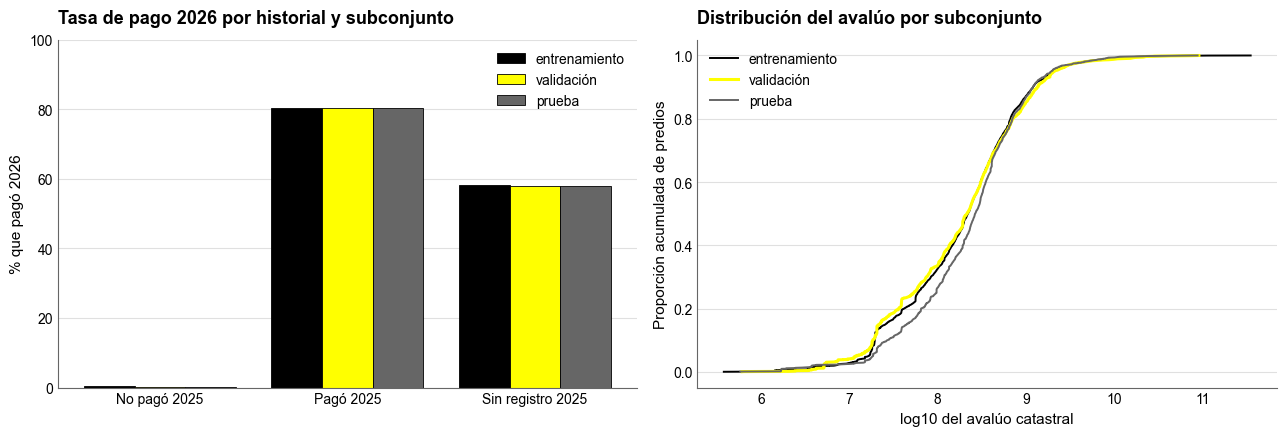

In [7]:
# Izquierda: tasa de pago 2026 por historial en cada subconjunto. Derecha: distribución acumulada del
# log-avalúo en cada subconjunto
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
tasa = preparados.groupby([um.GRUPO, subconjunto])[um.OBJETIVO].mean().unstack()[ORDEN] * 100
colores = {"entrenamiento": um.NEGRO, "validación": um.AMARILLO, "prueba": um.GRIS}
x = np.arange(len(tasa))
for k, nombre in enumerate(ORDEN):
    ax1.bar(x + (k - 1) * 0.27, tasa[nombre], width=0.27, color=colores[nombre], edgecolor=um.NEGRO,
            linewidth=0.6, label=nombre)
ax1.set_xticks(x, tasa.index)
ax1.set_ylabel("% que pagó 2026"); ax1.set_ylim(0, 100)
ax1.set_title("Tasa de pago 2026 por historial y subconjunto"); ax1.legend()

for nombre in ORDEN:
    valores = np.sort(preparados.loc[subconjunto == nombre, "log_avaluo"].dropna())
    ax2.plot(valores, np.arange(1, len(valores) + 1) / len(valores), color=colores[nombre],
             linewidth=2.2 if nombre == "validación" else 1.4, label=nombre)
ax2.set_xlabel("log10 del avalúo catastral"); ax2.set_ylabel("Proporción acumulada de predios")
ax2.set_title("Distribución del avalúo por subconjunto"); ax2.legend()
plt.tight_layout(); plt.show()

**Interpretación.** Los tres subconjuntos conservan la distribución del conjunto completo en lo que se estratificó, y se apartan poco en lo demás.

- **Estratificadas.** La variable objetivo, el historial y la condición del predio tienen las mismas proporciones en los tres (chi-cuadrado ≈ 0, p = 1): 64,9 % pagó 2026, y la tasa de pago de cada historial es igual en entrenamiento, validación y prueba (gráfica izquierda).
- **Otras categóricas.** La novedad, la destinación y la zona dan p < 0,05, pero con V de Cramér de 0,07 o menos: diferencias pequeñas, que vienen de que los dueños grandes caen enteros en un solo subconjunto. El resultado de la visita no se asocia con el subconjunto (p = 0,15).
- **Numéricas.** Kolmogórov-Smirnov rechaza $H_0$ en varias, pero con estadísticos de 0,10 o menos y medianas parecidas (el log10 del avalúo: 8,34 en entrenamiento, 8,33 en validación y 8,43 en prueba). Con miles de predios, la prueba detecta diferencias que no tienen importancia práctica. Las curvas acumuladas del avalúo casi se superponen (gráfica derecha).

Es el costo de no repartir a los dueños grandes: los subconjuntos son algo menos parecidos entre sí que con una partición al azar, pero la evaluación no premia al modelo por reconocer dueños que ya vio.

<a id="guardar"></a>

## 6. Guardar la partición

Un archivo con `id_predio` y el subconjunto de cada predio, para que el notebook 10 use exactamente la misma partición. Al final, la evidencia de la matriz que recibe el modelo: el preprocesador del notebook 08 (`um.crear_preprocesador`) ajustado solo con entrenamiento y aplicado a validación y prueba.

In [8]:
particion = pd.DataFrame({"id_predio": preparados["id_predio"], "subconjunto": subconjunto})
assert particion["id_predio"].is_unique and len(particion) == len(preparados)
particion.to_parquet(um.ARCHIVO_PARTICION, index=False)
print(f"Guardado en {um.ARCHIVO_PARTICION.relative_to(um.RAIZ)}")
particion["subconjunto"].value_counts()[ORDEN].to_frame("predios")

Guardado en datos\modelado\particion.parquet


,predios
subconjunto,
entrenamiento,13161
validación,2821
prueba,2820


In [9]:
# El preprocesador se ajusta solo con entrenamiento y se aplica a los otros dos subconjuntos
preprocesador = um.crear_preprocesador().fit(preparados.loc[subconjunto == "entrenamiento", um.CARACTERISTICAS])
nombres = pd.Series(preprocesador.get_feature_names_out())
matrices = {nombre: preprocesador.transform(preparados.loc[subconjunto == nombre, um.CARACTERISTICAS])
            for nombre in ORDEN}
display(pd.DataFrame({nombre: {"filas": m.shape[0], "columnas": m.shape[1], "faltantes": int(np.isnan(m).sum())}
                      for nombre, m in matrices.items()}).T)
print("Columnas por tipo de transformación:", nombres.str.split("__").str[0].value_counts().to_dict())

# Las numéricas estandarizadas: media 0 y desviación 1 en entrenamiento, y cerca de eso en los otros dos
numericas = nombres.str.startswith("numericas__").to_numpy()
pd.DataFrame({nombre: {"media": m[:, numericas].mean(), "desviación media": m[:, numericas].std(axis=0).mean()}
              for nombre, m in matrices.items()}).T.round(3)

,filas,columnas,faltantes
entrenamiento,13161,57,0
validación,2821,57,0
prueba,2820,57,0


Columnas por tipo de transformación: {'categoricas': 34, 'numericas': 18, 'binarias': 5}


,media,desviación media
entrenamiento,0.00,1.00
validación,-0.02,0.96
prueba,0.04,0.92


**Interpretación.** Ajustado solo con entrenamiento, el preprocesador produce 57 columnas: 34 del one-hot, 18 de las numéricas (12 variables y 6 indicadores de faltante) y las 5 binarias. Validación y prueba se transforman sin errores ni faltantes, aunque tengan categorías que entrenamiento no vio. Las numéricas quedan con media 0 y desviación 1 en entrenamiento, y cerca de eso en validación y prueba (desviación media de 0,96 y 0,92), como se espera cuando la media y la desviación salen solo de entrenamiento.